# LendingClub: прогноз дефолта по займу — проект по шагам

Итоговый проект по дисциплине **Programming for Data Analysis and Database**, тема №33.
Автор: Kilybayev Yersaiyn, AAI-2602M.

Этот ноутбук проходит весь проект в том же порядке, что и консольное меню `main.py`.
Он **не дублирует код**: каждая ячейка вызывает функции из папки `src/`, те же самые, что работают в меню и в дашборде.

**Как читать результаты.** Ноутбук считает всё на демо-выборке из репозитория (50 тыс. займов), поэтому запускается
за 1–2 минуты и без скачивания данных. В выборке созревшие займы взяты с запасом, поэтому её числа
**не отражают полный набор**. Итоговые результаты проекта получены на всех 2,26 млн займов; они лежат в `reports/`
и показаны в ноутбуке отдельно, с пометкой «полный запуск».

**Как запустить.** Откройте файл в VS Code или Jupyter из корня проекта и выполните все ячейки по порядку
(нужны библиотеки из `requirements.txt`). Результаты ноутбука пишутся в `sample_run/` и не меняют файлы в `reports/`.

In [1]:
# Только для Google Colab: снимите комментарии, чтобы скачать проект и установить библиотеки.
# !git clone https://github.com/yersaa/Loan_default_prediction.git
# %cd Loan_default_prediction
# !pip install -q -r requirements.txt

## 0. Настройка

`src/config.py` хранит все пути и списки колонок. `activate_sample()` переключает проект на демо-выборку.

In [2]:
import warnings

import pandas as pd
from IPython.display import Image, display

from src import config as C
from src.data_io import load_dataset, load_json, mb

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
warnings.filterwarnings("ignore", message="IProgress not found")  # SHAP ищет виджет прогресса, он здесь не нужен

PUBLISHED = C.ROOT / "reports"   # результаты полного запуска на 2,26 млн займов
C.activate_sample()              # дальше всё считается на демо-выборке, результаты идут в sample_run/
for folder in (C.REPORTS, C.FIGURES, C.MODELS):
    folder.mkdir(parents=True, exist_ok=True)


def show(name: str, width: int = 850) -> None:
    """Показывает график полного запуска из reports/figures."""
    display(Image(filename=str(PUBLISHED / "figures" / name), width=width))


print("Данные:", C.PARQUET.relative_to(C.ROOT))
print("Результаты ноутбука:", C.REPORTS.relative_to(C.ROOT))

Данные: data\sample\loans_sample.parquet
Результаты ноутбука: sample_run\reports


## 1. Данные: чтение частями, Parquet, оптимизация типов

Исходный файл Kaggle — `accepted_2007_to_2018Q4.csv.gz`: 2,26 млн строк, 151 колонка. Целиком в память он не помещается
(около 3 ГБ), поэтому `src/data_io.py`, функция `csv_to_parquet`:

1. читает CSV частями по 250 тыс. строк (`pd.read_csv(..., chunksize=...)`) и только 33 нужные колонки;
2. чистит каждую часть (`clean_chunk`) и дописывает её в один файл Parquet;
3. заменяет прежний файл только после успешной записи всех частей.

Демо-выборка уже лежит в Parquet, поэтому здесь показан результат полного запуска, а затем загрузка выборки.

In [3]:
ingest = load_json(PUBLISHED / "ingest.json")
pd.Series(ingest, name="полный запуск", dtype="object").to_frame()

,полный запуск
rows_raw,2260701
rows,2260668
seconds,32.5
csv_gz_mb,374.4
parquet_mb,76.0


In [4]:
df = load_dataset()
print(f"Строк: {len(df):,}   колонок: {df.shape[1]}   в памяти: {mb(df)} МБ")
df.head(3)

Строк: 50,000   колонок: 33   в памяти: 5.5 МБ


,id,issue_d,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,loan_status,total_pymnt,recoveries,last_pymnt_d
0,110627,2007-07-01,1000.0,36 months,15.01,34.680000,F,F1,1 year,RENT,17280.0,Not Verified,debt_consolidation,MO,20.000000,0.0,2004-08-01,650.0,654.0,2.0,12.0,0.0,2484.0,35.400002,22.0,f,Individual,NaN,NaN,Does not meet the credit policy. Status:Fully ...,1248.176270,0.0,2010-07-01
1,106079,2007-07-01,3500.0,36 months,9.96,112.870003,B,B5,< 1 year,RENT,13500.0,Not Verified,educational,FL,16.440001,0.0,2002-12-01,710.0,714.0,1.0,10.0,0.0,2864.0,41.099998,16.0,f,Individual,NaN,NaN,Fully Paid,3942.013184,0.0,2009-03-01
2,99009,2007-07-01,5750.0,36 months,7.43,178.690002,A,A2,10+ years,MORTGAGE,125000.0,Not Verified,debt_consolidation,MA,0.270000,0.0,1987-01-01,790.0,794.0,0.0,10.0,0.0,2817.0,10.200000,16.0,f,Individual,NaN,NaN,Fully Paid,6421.743164,0.0,2010-05-01


**Оптимизация типов.** `optimize_dtypes` хранит строки с малым числом значений как `category`, а числа как `float32`.
Сравним ту же таблицу с обычными типами `object` и `float64`:

In [5]:
plain = df.astype({c: "object" for c in C.CATEGORICAL} | {c: "float64" for c in C.FLOAT32})
print(f"Обычные типы: {mb(plain)} МБ   оптимизированные: {mb(df)} МБ   экономия в {mb(plain) / mb(df):.1f} раза")
del plain

Обычные типы: 41.8 МБ   оптимизированные: 5.5 МБ   экономия в 7.6 раза

In [6]:
memory = load_json(PUBLISHED / "benchmarks.json")["memory"]["full_dataset_estimate_mb"]
sizes = {"все 151 колонка": memory["all_cols"], "33 нужные колонки": memory["selected_cols"],
         "33 колонки + category/float32": memory["selected_optimized"]}
pd.Series(sizes, name="память на полном наборе, МБ").to_frame()

,"память на полном наборе, МБ"
все 151 колонка,3084
33 нужные колонки,786
33 колонки + category/float32,248


## 2. Аудит качества данных

`src/audit.py`, функция `run_audit`: пропуски, дубликаты, некорректные значения и выбросы по правилу 1,5·IQR.
По результатам аудита заданы правила очистки в `src/features.py`, `clean_values`.

In [7]:
from src.audit import run_audit

audit = run_audit(df)
print("Дубликатов id:", audit["duplicate_ids"])
pd.Series(audit["missing_pct"], name="пропуски, %").head(8).to_frame()

Дубликатов id: 0


,"пропуски, %"
emp_length,5.88
mort_acc,5.30
pub_rec_bankruptcies,0.17
last_pymnt_d,0.06
revol_util,0.06
dti,0.04


In [8]:
pd.Series(audit["invalid_values"], name="строк с нарушением").to_frame()

,строк с нарушением
annual_inc <= 0,17
dti < 0 или >= 999,2
revol_util > 150%,1
fico_range_low > fico_range_high,0
earliest_cr_line позже issue_d,0
int_rate вне 5–31%,0


In [9]:
published_audit = load_json(PUBLISHED / "audit.json")
pd.Series(published_audit["invalid_values"], name="полный запуск: строк с нарушением").to_frame()

,полный запуск: строк с нарушением
annual_inc <= 0,1667
dti < 0 или >= 999,137
revol_util > 150%,28
fico_range_low > fico_range_high,0
earliest_cr_line позже issue_d,0
int_rate вне 5–31%,0


## 3. Целевая переменная, созревшие займы и разбиение по времени

`src/features.py`:

- `add_target`: `Fully Paid` → 0, `Charged Off` / `Default` → 1, остальные статусы — займ ещё не завершён;
- `is_matured`: срок займа истёк к декабрю 2018 г. Просто убрать статус `Current` нельзя: среди незрелых займов
  завершены только досрочно погашенные и уже списанные, и дефолтность по ним смещена;
- `build_features`: новые признаки из полей анкеты (`fico`, `credit_hist_months`, `loan_to_income` и др.);
- `temporal_split`: окна по году выдачи, без перемешивания.

In [10]:
from src.features import modeling_frame, temporal_split

model_df = modeling_frame(df.copy())
windows = temporal_split(model_df)
summary = {}
for name, window in windows.items():
    years = sorted(window["issue_d"].dt.year.unique())
    summary[name] = {"годы выдачи": str(years[0]) if len(years) == 1 else f"{years[0]}–{years[-1]}",
                     "займов": len(window), "дефолт, %": round(100 * float(window[C.TARGET].mean()), 2)}
pd.DataFrame(summary).T

,годы выдачи,займов,"дефолт, %"
fit,2007–2013,11888,15.26
valid,2014,8438,13.23
train,2007–2014,20326,14.42
test,2015,14674,14.56


`fit` и `valid` — части `train`. На `fit` подбираются гиперпараметры, на `valid` — калибровка, порог и выбор модели.
`test` используется один раз, для итоговой оценки.

**Проверка на утечку.** В модель идут только поля, известные до выдачи займа. Пересечение списка признаков
со списком полей, которые появляются после выдачи, должно быть пустым:

In [11]:
print("Признаков:", len(C.FEATURES))
print("Пересечение с полями после выдачи:", set(C.FEATURES) & set(C.LEAKAGE_COLS) or "пусто")
print("Назначает LendingClub, а не заёмщик:", sorted(C.LC_ASSIGNED))

Признаков: 28
Пересечение с полями после выдачи: пусто
Назначает LendingClub, а не заёмщик: ['grade', 'initial_list_status', 'installment', 'installment_to_income', 'int_rate', 'sub_grade', 'verification_status']


## 4. База данных SQLite и SQL-запросы

`src/database.py`, функция `build_database`, раскладывает плоскую таблицу по нормализованной схеме из `sql/schema.sql`:
четыре справочника и три таблицы — `loans` (условия займа), `borrowers` (профиль заёмщика), `outcomes` (исход).

![ER-диаграмма](docs/er_diagram.png)

In [12]:
from src.database import build_database, load_queries, run_all_queries, run_query

build_database(df.copy())

  dim_grade             35 строк
  dim_purpose           14 строк
  dim_state             50 строк
  dim_home               6 строк


  loans             50,000 строк
  borrowers         50,000 строк


  outcomes          50,000 строк


{'dim_grade': 35,
 'dim_purpose': 14,
 'dim_state': 50,
 'dim_home': 6,
 'loans': 50000,
 'borrowers': 50000,
 'outcomes': 50000,
 'seconds': 1.1,
 'db_mb': 12.1}

Запросы лежат в `sql/queries.sql`. `load_queries` читает файл в словарь `{имя: текст SQL}`,
`run_query` выполняет запрос и возвращает результат в Pandas.

In [13]:
queries = load_queries()
print(len(queries), "запросов:", ", ".join(queries))
print()
print(queries["state_rank"])

10 запросов: default_by_grade, purpose_having, vintage_by_year_term, state_rank, monthly_rolling, yoy_volume_lag, dti_deciles, income_vs_grade_avg, loss_by_grade, fico_home_matrix

-- 4. CTE + оконные RANK(): рейтинг штатов по дефолтности в целом и внутри региона
WITH state_stats AS (
    SELECT s.state_code, s.region,
           COUNT(*)                          AS loans,
           ROUND(AVG(o.is_default) * 100, 2) AS default_rate_pct
    FROM loans l
    JOIN outcomes o  ON o.loan_id = l.loan_id
    JOIN dim_state s ON s.state_code = l.state_code
    WHERE o.is_default IS NOT NULL AND o.is_matured = 1
    GROUP BY s.state_code, s.region
    HAVING COUNT(*) >= 1000
)
SELECT *,
       RANK() OVER (ORDER BY default_rate_pct DESC)                     AS rank_overall,
       RANK() OVER (PARTITION BY region ORDER BY default_rate_pct DESC) AS rank_in_region
FROM state_stats
ORDER BY rank_overall;


In [14]:
run_query("state_rank").head(8)

,state_code,region,loans,default_rate_pct,rank_overall,rank_in_region
0,OH,Midwest,1152,16.23,1,1
1,FL,South,2527,16.22,2,1
2,NJ,Northeast,1295,15.06,3,1
3,CA,West,5478,15.04,4,1
4,NY,Northeast,2962,14.42,5,2
5,VA,South,1043,14.38,6,2
6,TX,South,2824,14.31,7,3
7,PA,Northeast,1195,14.14,8,3


In [15]:
results = run_all_queries()

  default_by_grade            7 строк   0.03 c
  purpose_having              2 строк   0.03 c


  vintage_by_year_term       21 строк   0.04 c
  state_rank                 10 строк   0.05 c
  monthly_rolling           102 строк   0.03 c


  yoy_volume_lag             48 строк   0.07 c


  dti_deciles                10 строк   0.08 c


  income_vs_grade_avg        14 строк   0.31 c
  loss_by_grade               7 строк   0.01 c
  fico_home_matrix           12 строк   0.05 c


**Полный запуск.** Дефолтность по грейдам (запрос `default_by_grade`) и доход относительно среднего по своему
подгрейду (запрос `income_vs_grade_avg`): внутри одного грейда заёмщики с доходом ниже среднего дефолтят чаще.

In [16]:
pd.read_csv(PUBLISHED / "sql" / "default_by_grade.csv")

,grade,loans,default_rate_pct,avg_int_rate
0,A,144214,5.50,7.23
1,B,220196,11.38,10.90
2,C,180210,18.31,14.08
3,D,87126,23.84,17.29
4,E,32147,29.41,20.12
5,F,10349,34.52,23.25
6,G,2060,37.43,24.30


In [17]:
income = pd.read_csv(PUBLISHED / "sql" / "income_vs_grade_avg.csv")
income.pivot(index="grade", columns="income_group", values="default_rate_pct")

income_group,above_avg,below_avg
grade,,
A,4.49,6.12
B,9.88,12.26
C,15.90,19.72
D,21.44,25.24
E,26.76,30.98
F,30.82,36.89
G,33.82,39.54


## 5. EDA и графики

`src/eda.py`, функция `run_eda`, строит шесть статических графиков и два интерактивных. Часть графиков берёт данные
прямо из SQL-запросов. Ячейка ниже строит их на выборке; показаны графики полного запуска.

In [18]:
from src.eda import run_eda

created = run_eda(df, model_df)
print(len(created), "файлов в", C.FIGURES.relative_to(C.ROOT))

14 файлов в sample_run\reports\figures


**Полный запуск.** Дефолтность растёт от грейда A к G вместе со ставкой: грейды LendingClub отражают риск.

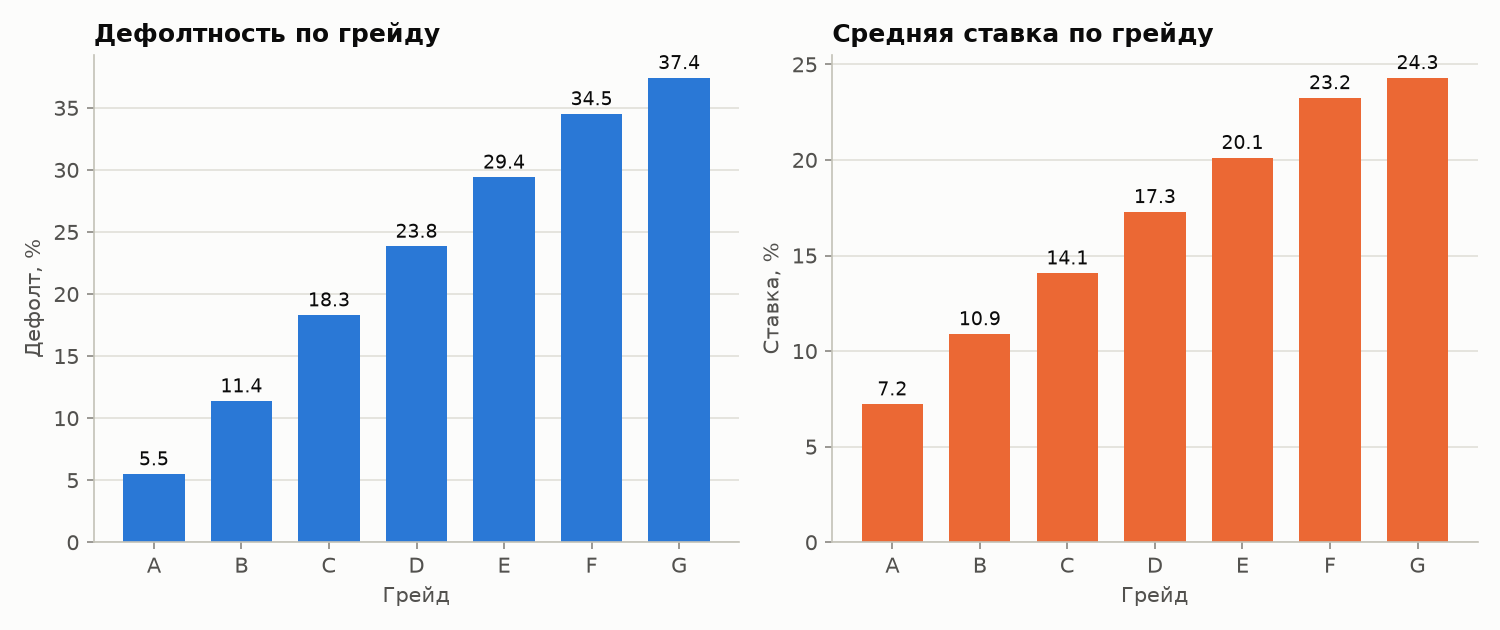

In [19]:
show("02_default_by_grade.png")

**Полный запуск.** Цензурирование: чем моложе займы, тем меньшая их доля завершена и тем выше дефолтность
среди завершённых. Поэтому в модель идут только созревшие займы.

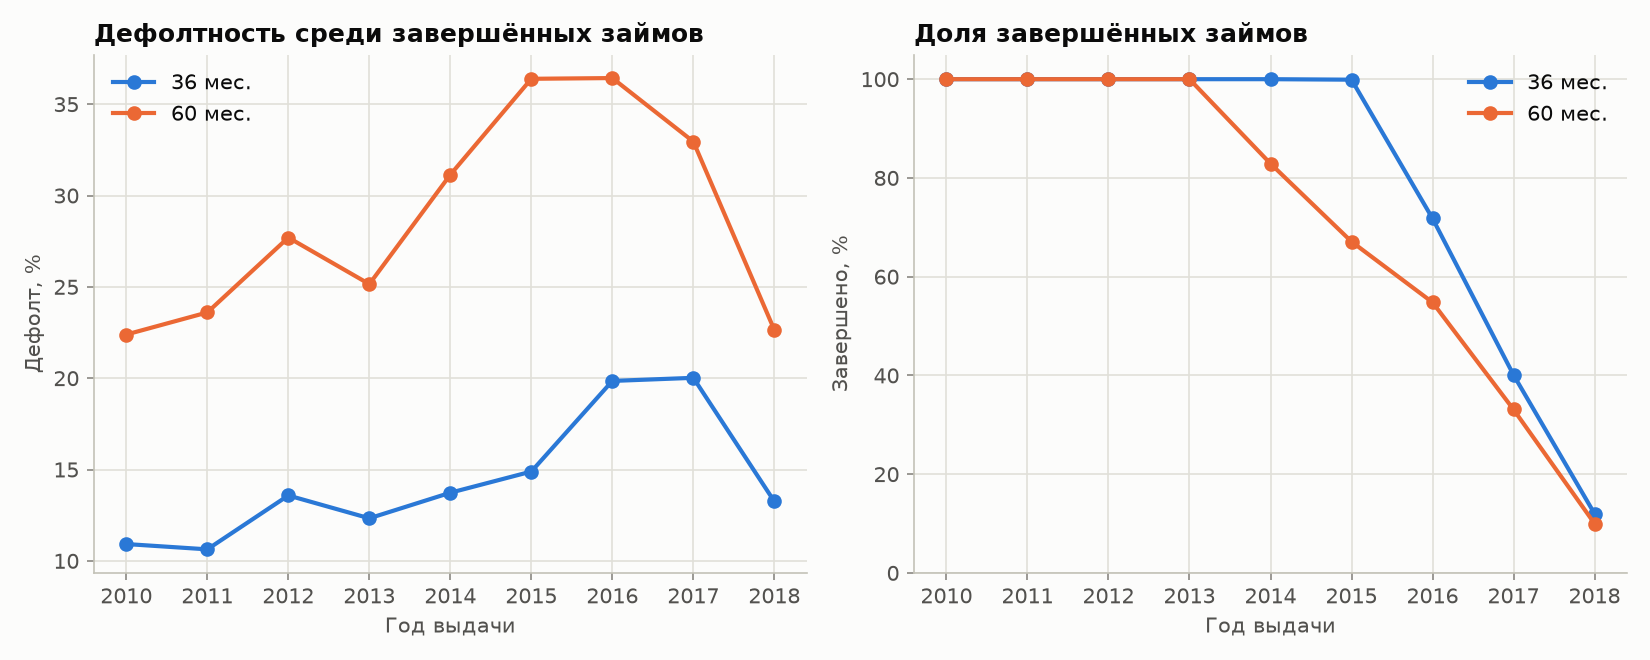

In [20]:
show("03_vintage.png")

## 6. Модели: подбор, обучение, сравнение

`src/models.py`. Сравниваются шесть моделей (`model_specs`):

| Модель | Роль |
|---|---|
| Dummy | baseline: константа, равная доле дефолтов |
| Только подгрейд LC | baseline: оценка самого LendingClub |
| Logistic Regression, LightGBM | все поля, известные до выдачи |
| Те же две модели | только поля, которые указывает заёмщик |

Сначала `tune` подбирает гиперпараметры на окне `fit` с разбиением по времени (`TimeSeriesSplit`).

In [21]:
from src.models import train_and_compare, tune

fit = windows["fit"]
best = tune(fit[C.FEATURES], fit[C.TARGET].astype(int))

  Logistic Regression: {'model__C': 0.05}  CV ROC-AUC=0.6653


  LightGBM: {'model__n_estimators': 300, 'model__num_leaves': 31}  CV ROC-AUC=0.6299


  Logistic Regression (borrower only): {'model__C': 0.05}  CV ROC-AUC=0.6560


  LightGBM (borrower only): {'model__n_estimators': 300, 'model__num_leaves': 31}  CV ROC-AUC=0.6258


`train_and_compare` для каждой модели вызывает `fit_one`:

1. пробная модель учится на `fit` и делает прогноз на `valid`; по нему подбираются калибровка Платта и порог;
2. финальная модель учится на `train` и оценивается на `test`.

In [22]:
metrics, fitted, preds, preds_raw, test = train_and_compare(model_df, best)
QUALITY = ["model", "valid_auc", "roc_auc", "gini", "ks", "pr_auc", "brier", "ece", "f1"]
metrics[QUALITY]

  Dummy (prior)                        ROC-AUC=0.5000  KS=0.000  fit=0.0c


  Grade only (LogReg)                  ROC-AUC=0.6741  KS=0.259  fit=0.0c


  Logistic Regression                  ROC-AUC=0.6804  KS=0.270  fit=0.3c


  LightGBM                             ROC-AUC=0.6640  KS=0.247  fit=0.6c


  Logistic Regression (borrower only)  ROC-AUC=0.6544  KS=0.220  fit=0.2c


  LightGBM (borrower only)             ROC-AUC=0.6499  KS=0.212  fit=0.5c


,model,valid_auc,roc_auc,gini,ks,pr_auc,brier,ece,f1
0,Dummy (prior),0.5000,0.5000,0.0000,0.0000,0.1456,0.1244,0.0015,0.2542
1,Grade only (LogReg),0.6568,0.6741,0.3481,0.2590,0.2412,0.1193,0.0224,0.3283
2,Logistic Regression,0.6658,0.6804,0.3608,0.2702,0.2519,0.1184,0.0136,0.3334
3,LightGBM,0.6307,0.6640,0.3279,0.2473,0.2331,0.1198,0.0200,0.3187
4,Logistic Regression (borrower only),0.6421,0.6544,0.3088,0.2202,0.2321,0.1200,0.0136,0.3130
5,LightGBM (borrower only),0.6197,0.6499,0.2999,0.2120,0.2331,0.1204,0.0203,0.2981


**Полный запуск** (test: 283 026 созревших займов 2015 г., дефолтность 14,9%). Это итоговая таблица проекта:

In [23]:
published = pd.read_csv(PUBLISHED / "model_metrics.csv")
published[QUALITY]

,model,valid_auc,roc_auc,gini,ks,pr_auc,brier,ece,f1
0,Dummy (prior),0.5000,0.5000,0.0000,0.0000,0.1489,0.1267,0.0003,0.2591
1,Grade only (LogReg),0.6595,0.6786,0.3573,0.2619,0.2505,0.1209,0.0202,0.3353
2,Logistic Regression,0.6733,0.6889,0.3778,0.2768,0.2612,0.1198,0.0105,0.3435
3,LightGBM,0.6772,0.6965,0.3930,0.2862,0.2735,0.1190,0.0116,0.3487
4,Logistic Regression (borrower only),0.6527,0.6588,0.3177,0.2285,0.2382,0.1218,0.0105,0.3207
5,LightGBM (borrower only),0.6632,0.6743,0.3486,0.2528,0.2526,0.1207,0.0103,0.3313


**Правило выбора модели** задано заранее в `config.SIMPLICITY_MARGIN_AUC` и применяется к валидации, а не к тесту:
берётся лучшая ROC-AUC на 2014 годе, но логистическая регрессия предпочитается, если отстаёт меньше чем на 0,005.

In [24]:
load_json(PUBLISHED / "model_selection.json")

{'rule': 'max valid_auc (2014); логрегрессия, если отстаёт меньше чем на 0.005',
 'best_by_valid_auc': 'LightGBM',
 'selected': 'Logistic Regression',
 'valid_auc': {'Logistic Regression': 0.6733,
  'LightGBM': 0.6772,
  'Logistic Regression (borrower only)': 0.6527,
  'LightGBM (borrower only)': 0.6632}}

**Время и память** (полный запуск). Память обучения замерена в отдельном процессе для каждой модели,
медиана трёх запусков (`src/benchmark.py`, `model_fit_memory`).

In [25]:
fit_memory = load_json(PUBLISHED / "benchmarks.json")["model_fit_memory"]
cost = published[["model", "fit_seconds", "predict_ms_per_1000", "model_mb"]].copy()
cost.insert(2, "fit_peak_mb", cost["model"].map(lambda name: fit_memory[name]["fit_peak_mb"]))
cost

,model,fit_seconds,fit_peak_mb,predict_ms_per_1000,model_mb
0,Dummy (prior),0.0307,8.1,0.0413,0.0012
1,Grade only (LogReg),0.5388,40.5,0.3269,0.0035
2,Logistic Regression,6.1426,400.9,3.7443,0.0097
3,LightGBM,5.6114,154.9,7.7632,1.0217
4,Logistic Regression (borrower only),4.0807,299.9,2.2865,0.0081
5,LightGBM (borrower only),4.2665,122.6,7.6246,1.0243


## 7. Интерпретация и анализ ошибок

`src/explain.py`, функция `run_explain`: ROC и PR, матрица ошибок, калибровка, SHAP, ошибки по грейдам, таблица одобрения.

In [26]:
from src.explain import run_explain

explained = run_explain(fitted, preds, preds_raw, test, metrics)
explained["errors"]

,grade,loans,actual_default_pct,predicted_pd_pct,auc_within_grade,missed_defaults_pct,false_alarms_pct
0,A,3654,5.34,7.80,0.61,96.41,1.42
1,B,4786,11.81,12.90,0.56,68.32,24.24
2,C,3966,18.96,15.92,0.56,39.10,53.11
3,D,1742,25.09,18.62,0.54,16.48,77.09
4,E,459,34.42,21.61,0.53,8.23,92.03
5,F,57,43.86,20.01,0.47,12.00,84.38
6,G,10,50.00,22.13,0.88,0.00,100.00


**Полный запуск.** ROC и Precision–Recall: все модели лучше Dummy, разница между сильнейшими невелика.

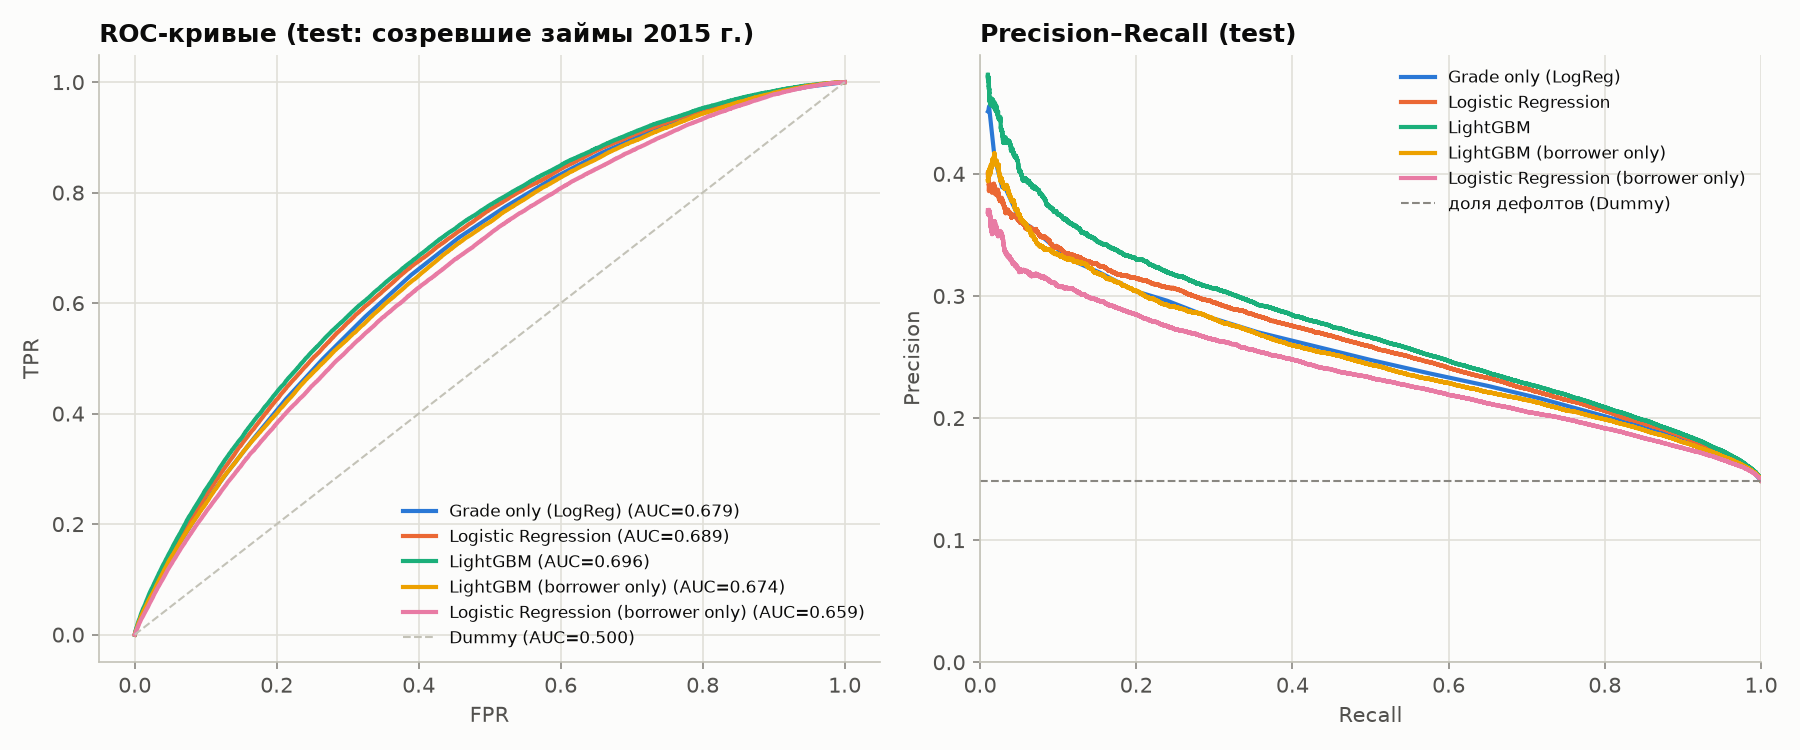

In [27]:
show("09_roc_pr.png")

**Полный запуск.** SHAP для LightGBM: самые важные признаки — подгрейд и ставка, то есть оценка самого LendingClub.

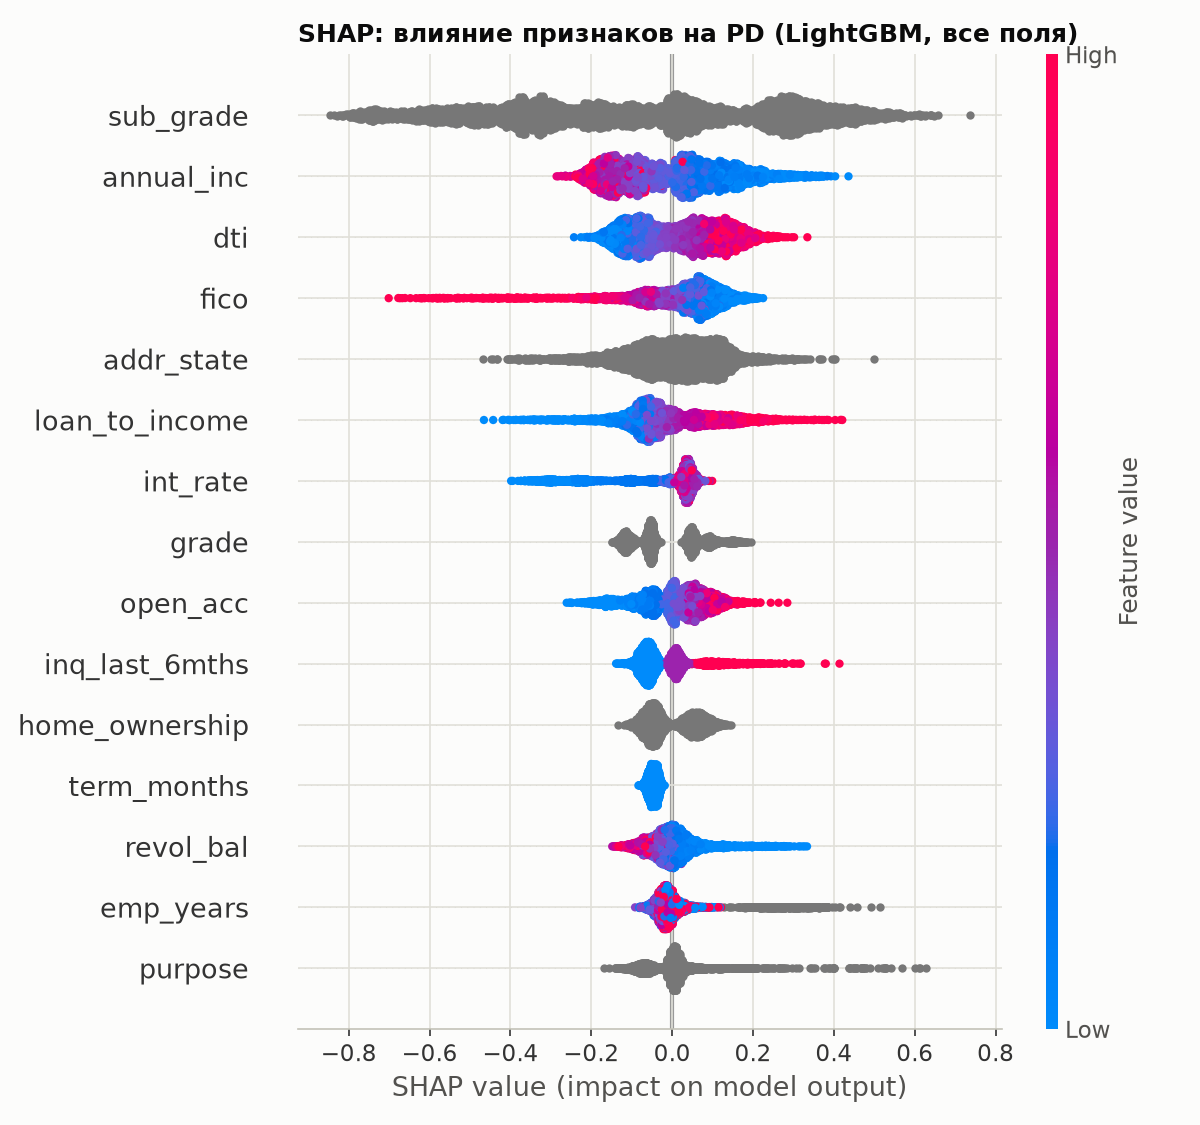

In [28]:
show("12_shap_summary.png", width=650)

**Полный запуск.** Таблица одобрения: если одобрять не все заявки, а долю с наименьшей вероятностью дефолта,
дефолтность портфеля снижается. Это практическая польза модели.

In [29]:
approval = pd.read_csv(PUBLISHED / "approval_table.csv")
approval.pivot(index="approval_rate", columns="model", values="default_rate_pct").round(1)

model,Grade only (LogReg),LightGBM,LightGBM (borrower only),Logistic Regression
approval_rate,,,,
0.5,8.2,7.7,8.5,8.0
0.6,9.4,8.9,9.7,9.1
0.7,10.6,10.1,10.8,10.3
0.8,11.9,11.4,11.9,11.6
0.9,13.2,12.9,13.2,13.1
1.0,14.9,14.9,14.9,14.9


## 8. Проверка: насколько цензурирование завышало результат

`src/censoring.py` обучает те же модели на «всех завершённых» займах. На полном наборе AUC на смещённой когорте
выше примерно на 0,04, но внутри 36-месячных займов она почти та же: завышение создаётся смешением сроков.

In [30]:
pd.read_csv(PUBLISHED / "censoring_sensitivity.csv")

,cohort,model,train_rows,test_rows,train_default_pct,test_default_pct,mean_pd_pct,test_auc,auc_36m,auc_60m
0,созревшие (основной),Logistic Regression,393276,283026,14.85,14.89,13.08,0.6889,0.6889,NaN
1,созревшие (основной),LightGBM,393276,283026,14.85,14.89,12.96,0.6965,0.6965,NaN
2,все завершённые (смещённый),Logistic Regression,453809,375546,17.03,20.19,17.43,0.7311,0.6899,0.6718
3,все завершённые (смещённый),LightGBM,453809,375546,17.03,20.19,17.33,0.7363,0.6971,0.6769


## 9. Оценка одной заявки

`predict_pd` проверяет анкету (`validate_application`), собирает строку признаков тем же кодом, что при обучении,
и возвращает калиброванную вероятность дефолта от каждой модели. Здесь используются модели, обученные выше на выборке.

In [31]:
from src.models import predict_pd

application = {
    "loan_amnt": 15000, "term_months": 36, "int_rate": 13.0, "sub_grade": "C1", "annual_inc": 65000, "dti": 18,
    "fico": 700, "emp_years": 5, "revol_util": 50, "inq_last_6mths": 1, "credit_hist_months": 180,
    "home_ownership": "RENT", "purpose": "debt_consolidation", "verification_status": "Source Verified",
    "addr_state": "CA", "initial_list_status": "w", "application_type": "Individual",
}
pd.DataFrame(predict_pd(application)).T

,pd,threshold,decision
LightGBM,0.164649,0.15,отказ
Logistic Regression,0.177359,0.14,отказ
LightGBM (borrower only),0.10495,0.15,одобрить


Некорректная анкета отклоняется с понятным сообщением (обработка ошибок через `try` / `except`):

In [32]:
try:
    predict_pd({**application, "fico": 300})
except ValueError as error:
    print("Ошибка:", error)

Ошибка: fico = 300: допустимо от 600 до 850


## 10. Сравнение способов обработки данных

Пункт меню 8 (`src/benchmark.py`) требует исходный CSV, поэтому здесь показан результат полного запуска.
Каждый замер идёт в отдельном процессе, в таблице медиана трёх запусков.

In [33]:
bench = load_json(PUBLISHED / "benchmarks.json")
rows = {
    "чтение 6 колонок: CSV.gz": bench["csv_vs_parquet"]["csv_gz"],
    "чтение 6 колонок: Parquet": bench["csv_vs_parquet"]["parquet"],
    "агрегация: Pandas + Parquet": bench["pandas_vs_sql"]["pandas_parquet"],
    "агрегация: SQLite": bench["pandas_vs_sql"]["sqlite"],
}
print("Результаты Pandas и SQL совпали:", bench["pandas_vs_sql"]["results_match"])
pd.DataFrame(rows).T[["seconds", "peak_mb"]].rename(columns={"seconds": "время, с", "peak_mb": "пик памяти, МБ"})

Результаты Pandas и SQL совпали: True


,"время, с","пик памяти, МБ"
чтение 6 колонок: CSV.gz,9.75,161.7
чтение 6 колонок: Parquet,0.23,244.0
агрегация: Pandas + Parquet,0.88,378.3
агрегация: SQLite,2.68,5.4


## Итог

- Parquet и оптимизация типов позволяют работать с 2,26 млн займов на обычном компьютере.
- Незавершённые 60-месячные займы завышали оценку качества, поэтому в модель идут только созревшие займы.
- По заранее заданному правилу выбрана логистическая регрессия: ROC-AUC 0,689 на займах 2015 года.
  LightGBM на тесте немного лучше (0,697), но менять выбор по тесту нельзя.
- Один подгрейд LendingClub (0,679) сильнее модели на всех полях заёмщика (0,674).

Полное описание методов, ограничений и выводов — в `docs/report.pdf`. Интерактивная версия аналитики и скоринга:
`streamlit run app.py`.